In [2]:
# -- Import Packages
#!/usr/bin/env python
%matplotlib inline  

#ipython magic to make wiphy module autoreload
%load_ext autoreload
%autoreload 2

#import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import pandas as pd
import time
import scipy.integrate as spi
import os
from sklearn.metrics import auc 
%matplotlib inline
#import warningsa
#warnings.filterwarnings("ignore")


import seaborn as sns
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu



# -- load data for all infections
#full_data_file = r'/Users/kowens2/Library/CloudStorage/OneDrive-FredHutchinsonCancerResearchCenter/Monolix/NBA Cohort/Data/NBA_1510infections.csv'
#full_data_df = pd.read_csv(full_data_file)

# -- Functions
def GetParams(parameters_df, ID, style = 'mode'):
    ''' 
    input:
        - data frame with parameter values as columns, individuals as rows
        - ID identifying individual of interest
        - style = 'mode' or 'mean' or 'SAEM' depending on which parameter values are preferred
    return:
        - dictionary with parameter names as key and parameter values as values
    '''
    i = ID
    cols = list(parameters_df)
    pid_params = parameters_df[parameters_df.id == i].copy()
    values = []
    keys = []
    for c in cols:
        if style in c:
            k = c.split('_')[0]
            keys.append(k)
            v = pid_params[c].values[0]
            values.append(v)
        for i,(v,k) in enumerate(zip(values, keys)):
            if 'log10' in k:
                values[i] = 10**v
                keys[i] = k.split('0')[1]

    params = dict(zip(keys, values))
    return params

def Simulate(func, param_order, param_dict, init, tend, N):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[5] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
V_0 = 0.075;
E_0 = 0;

init = [T_0, Ie_0,Ip_0, R_0, V_0,E_0]

# Write function for model simulation
def deriv(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T -eta*R
    ddt_V = p*Ip-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

param_order = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r']

def derivBUB(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R =  phi*Ip*T -eta*R
    ddt_Vb = p*Ip - delta*Vb - rho*Vb
    ddt_V = rho*Vb-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E


def derivOseltamivir(y, t, beta, phi, eta,gamma, delta,k,p,c,theta,h,r, treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb, ddt_V, ddt_E

def derivBaloxavir(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r, treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = 0
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb, ddt_V, ddt_E

param_order_treatment = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r',
                         'treat_start', 'treat_end', 'avg_efficacy']

def SimulateTreatment(func, param_order, param_dict, init, tend, N, treat_start, treat_end, avg_efficacy):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # add treatment parameters
    params.append(treat_start)
    params.append(treat_end)
    params.append(avg_efficacy)
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[6] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y
Vb_0 = 0
initTreatment = [T_0, Ie_0,Ip_0, R_0, Vb_0, V_0, E_0]

In [3]:
#parameters_df = pd.read_csv('/Users/kowens2/Library/CloudStorage/OneDrive-FredHutchinsonCancerResearchCenter/Influenza/estimatedIndividualParameters-Best.txt')
#data_df = pd.read_csv('FLU_ALL_un_censored.csv')

#################################
## Fixed c, beta, h parameters - Pre-run (Best fit) ##
#################################
M4a_shifted_Hill8_fixed_c_Owens = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/M4a_shifted_Hill8_fixed_c_Owens/IndividualParameters"
file_path = os.path.join(M4a_shifted_Hill8_fixed_c_Owens, "estimatedIndividualParameters.txt")

#################################
## Fixed c, beta, h, r, and a-error parameter
#################################
#M4a_fixed_c_beta_a0_99_rpop = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/Uncensored/Fixed Error a/M4a_shifted_Hill8_fixed_c_beta_a0.99_rpop/Assessment/Assessment_003/Assessment_003"
#file_path = os.path.join(M4a_fixed_c_beta_a0_99_rpop, "IndividualParameters/estimatedIndividualParameters.txt")

# parameters read in 
parameters_df = pd.read_csv(file_path, header = 0, sep = ",")

# volunteer observed vl data
data_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Data_IAV Model/FLU_ALL_un_censored.csv")

IDs = data_df.ID.unique()
colorDict = {0:'cornflowerblue',1:'tab:red'}

print(IDs)
print(parameters_df.head())
print(data_df.head())

['4A' '12A' '18A' '30A' '33A' '48A' '52A' '61A' '67A' '71A' '77A' '14B-A'
 '16B-A' '18B-A' '21B-A' '28B-A' '49B-A' '53B-A' '60B-A' '65B-A' '66B-A'
 '4B-B' '12B-B' '15B-B' '19B-B' '207B-B' '213B-B' '304B-B' '312B-B'
 '317B-B' '327B-B' '329B-B' '331B-B' '336B-B' '337B-B' '342B-B' '344B-B'
 '350B-B' '53B-B' '55B-B' '62B-B' '65B-B' '70B-B' '73B-B']
    id  log10beta_SAEM  delta_SAEM  log10p_SAEM  c_SAEM  gamma_SAEM  \
0   4A        -5.64272     1.10239      1.36365      15     6.30362   
1  12A        -5.70133     1.08271      1.37004      15     6.31936   
2  18A        -5.65362     1.07810      1.37866      15     6.23022   
3  30A        -5.74632     1.09067      1.36463      15     6.19980   
4  33A        -5.76658     1.08912      1.36921      15     6.16949   

   log10eta_SAEM  log10phi_SAEM  theta_SAEM   r_SAEM  ...  gamma_sd  \
0      -0.179895       -3.27652     1.90773  20.8716  ...  0.613825   
1      -0.163086       -3.75961     2.15401  88.9302  ...  0.534372   
2       0.218

In [4]:
## Simulate through all compartments for all three therapies

M = len(IDs)

# Get time vector once
params_dict_temp = GetParams(parameters_df, IDs[0], style='mode')
t, _ = Simulate(deriv, param_order, params_dict_temp, init, 40, 10000)

N = len(t)

# Storage for Ip cells: (M individuals × N timepoints)
Ip_untreated = np.zeros((M, N))
Ip_oselt     = np.zeros((M, N))
Ip_balox     = np.zeros((M, N))


# Storage for infected term: beta*T*V (M individuals x 
infectivity_unt = np.zeros((M, N))
infectivity_oselt = np.zeros((M, N))
infectivity_balox = np.zeros((M, N))

for i, ID in enumerate(IDs):
    params_dict = GetParams(parameters_df, ID, style='mode')
    beta = params_dict['beta']
    
    treat_start = np.random.uniform(1.5, 3.5)
    treat_end   = treat_start + 5
    avg_efficacy = 0.99

    # --- Untreated ---
    t, y = Simulate(deriv, param_order, params_dict, init, 40, 10000)
    Ip_untreated[i, :] = y[:, 2]
    infectivity_unt[i, :] = beta * y[:,0] * y[:,4]              # beta * T * V

    # --- Oselt ---
    tt, ytO = SimulateTreatment(
        derivOseltamivir, param_order, params_dict, initTreatment, 40, 10000, treat_start, treat_end, avg_efficacy)
    Ip_oselt[i, :] = ytO[:, 2]
    infectivity_oselt[i, :] = beta * ytO[:,0] * ytO[:,5]        # beta*T*Vu

    # --- Balox ---
    ttB, ytB = SimulateTreatment(
        derivBaloxavir, param_order, params_dict, initTreatment, 40, 10000, treat_start, treat_end, avg_efficacy
    )
    Ip_balox[i, :] = ytB[:, 2]
    infectivity_balox[i, :] = beta * ytB[:,0] * ytB[:,5]          # beta*T*V

print(Ip_untreated.shape)
print(infectivity_unt)
print(infectivity_oselt)

(44, 10000)
[[ 1.65132009e+00  1.55520144e+00  1.46500404e+00 ...  9.55476192e-18
   3.73349741e-18 -2.06721727e-18]
 [ 1.41250913e+00  1.33028301e+00  1.25307631e+00 ...  2.87457833e-18
   2.93098103e-18  2.98602481e-18]
 [ 1.63414754e+00  1.53902766e+00  1.44976289e+00 ... -4.91657809e-19
  -4.91455010e-19 -4.91251699e-19]
 ...
 [ 1.00795528e+00  9.49268651e-01  8.94102690e-01 ...  1.95506494e-14
   1.95733801e-14  1.95960979e-14]
 [ 8.28211513e-01  7.79986664e-01  7.34634541e-01 ... -4.10946152e-17
  -4.10112614e-17 -4.09272625e-17]
 [ 5.71730371e-01  5.38436842e-01  5.07109361e-01 ... -1.72266832e-23
  -1.81450396e-23 -1.90601075e-23]]
[[ 1.65132009e+00  1.55520144e+00  1.46500404e+00 ... -3.16738499e-17
  -3.36300140e-17 -3.55898850e-17]
 [ 1.41250913e+00  1.33028301e+00  1.25307631e+00 ...  1.58392892e-09
   1.63309659e-09  1.68541258e-09]
 [ 1.63414754e+00  1.53902766e+00  1.44976289e+00 ...  7.96523729e-22
   7.96491540e-22  7.96459352e-22]
 ...
 [ 1.00795528e+00  9.49268651e-0

In [5]:
def compute_log_ci(data):
    EPS = 1e-10
    log_data = np.log10(np.maximum(data, EPS))

    mean = np.mean(log_data, axis=0)
    std  = np.std(log_data, axis=0, ddof=1)
    sem  = std / np.sqrt(data.shape[0])
    ci   = 1.96 * sem

    return mean, mean - ci, mean + ci

In [6]:
# Determine 95% CI for simulated Ip population for all three therapies
mean_unt, low_unt, up_unt = compute_log_ci(Ip_untreated)
mean_os,  low_os,  up_os  = compute_log_ci(Ip_oselt)
mean_bx,  low_bx,  up_bx  = compute_log_ci(Ip_balox)


print(mean_unt.shape, low_unt.shape, up_unt.shape)
print(mean_unt)

(10000,) (10000,) (10000,)
[-10.          -4.37514772  -3.78628632 ...  -9.47992594  -9.4799261
  -9.47992626]


In [7]:
# Determine 95% CI for simulated Infectivity Rate (beta*T*V) for all three therapies
infectivity_mean_unt, infectivity_low_unt, infectivity_upper_unt = compute_log_ci(infectivity_unt)
infectivity_oselt_mean, infectivity_oselt_low, infectivity_oselt_upper = compute_log_ci(infectivity_oselt)
infectivity_balox_mean, infectivity_balox_low, infectivity_balox_upper = compute_log_ci(infectivity_balox)

print(infectivity_mean_unt.shape)
print(infectivity_mean_unt)
print(infectivity_oselt_mean.shape)
print(infectivity_balox_mean)

(10000,)
[-0.04494169 -0.07099455 -0.09700159 ... -9.43465965 -9.43465976
 -9.43465987]
(10000,)
[-0.04494169 -0.07099455 -0.09700159 ... -8.36519503 -8.36547552
 -8.36575602]


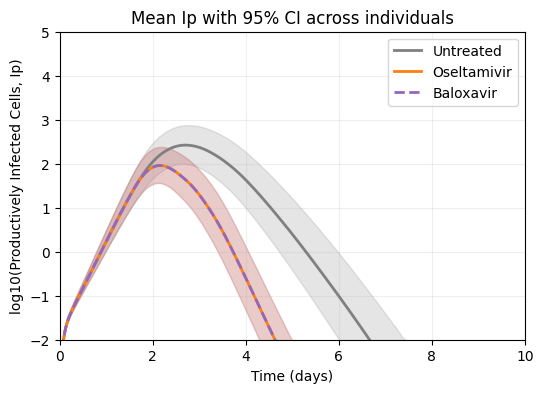

In [8]:
# ------------------------------------------------------------ #
# ---- Plotting: Infected Cells for all three therapies -------#
# ------------------------------------------------------------ #
plt.figure(figsize=(6,4))

# Untreated
plt.plot(t, mean_unt, color='gray', label='Untreated', linewidth=2)
plt.fill_between(t, low_unt, up_unt, color='gray', alpha=0.2)

# Oselt
plt.plot(t, mean_os, color='tab:orange', label='Oseltamivir', linewidth=2)
plt.fill_between(t, low_os, up_os, color='tab:orange', alpha=0.2)

# Balox
plt.plot(t, mean_bx, color='tab:purple', label='Baloxavir', linewidth=2, ls = "--")
plt.fill_between(t, low_bx, up_bx, color='tab:purple', alpha=0.2)

plt.xlabel("Time (days)")
plt.ylabel("log10(Productively Infected Cells, Ip)")
plt.xlim(0, 10)
plt.ylim(-2, 5)

plt.legend()
plt.grid(alpha=0.2)

plt.title("Mean Ip with 95% CI across individuals")
plt.show()

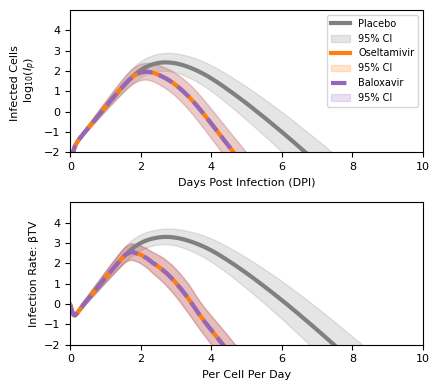

In [97]:
plt.rc('xtick', labelsize = 8)
plt.rc('ytick', labelsize = 8)        
fig, axes = plt.subplots(2, 1, figsize=(4.5, 4))
fig.subplots_adjust(hspace = 0.3)
axes = axes.flatten()

# ---- Plotting: Infected Cell, Ip, population all three therapies -------#
# ---------------------------------------------------------------------------------- #
ax = axes[0]
# Untreated
ax.plot(t, mean_unt, color='gray', label='Placebo', linewidth=3)
ax.fill_between(t, low_unt, up_unt, color='gray', alpha=0.2, label = '95% CI')

# Oselt
ax.plot(t, mean_os, color='tab:orange', label='Oseltamivir', linewidth=3)
ax.fill_between(t, low_os, up_os, color='tab:orange', alpha=0.2, label = '95% CI')

# Balox
ax.plot(t, mean_bx, color='tab:purple', label='Baloxavir', linewidth=3, ls = "--")
ax.fill_between(t, low_bx, up_bx, color='tab:purple', alpha=0.2, label = '95% CI')

ax.set_xlabel("Days Post Infection (DPI)", fontsize = 8)
ax.set_ylabel("Infected Cells \n log$_{10}(I_p)$", fontsize = 8)
ax.set_xlim(0, 10)
ax.set_ylim(-2, 5)
ax.set_yticks([-2, -1, 0, 1, 2, 3, 4])

ax.legend(fontsize = 7, loc = 'upper right'
          #, bbox_to_anchor = (1.2,1)
         )
ax.grid(False, 
        #alpha=0.2
       )

#ax.set_title("Average Productively Infected Cell Population", fontsize = 16, weight = "bold")

#---------------------------------------------------------------------------------- #
# ---- Plotting: Infectivity Rates for all three therapies -------#
# ---------------------------------------------------------------------------------- #
ax = axes[1]
# Untreated
ax.plot(t, infectivity_mean_unt, color='gray', label='Placebo', linewidth=3)
ax.fill_between(t, infectivity_low_unt, infectivity_upper_unt, color='gray', alpha=0.2, label = '95% CI')

# Oselt
ax.plot(t, infectivity_oselt_mean, color = 'tab:orange', label = 'Oseltamivir', linewidth = 3)
ax.fill_between(t, infectivity_oselt_low, infectivity_oselt_upper, color = 'orange', alpha = 0.2, label = '95% CI')


# Balox
ax.plot(t, infectivity_balox_mean, color = 'tab:purple', label = 'Baloxavir', linewidth = 3, ls = "--")
ax.fill_between(t, infectivity_balox_low, infectivity_balox_upper, color = 'purple', alpha = 0.2, label = '95% CI')

# ---------------------------------------------------------------------------------- #

ax.set_xlabel("Per Cell Per Day", fontsize = 8)
ax.set_ylabel("Infection Rate: βTV", fontsize = 8)

ax.set_xlim(0, 10)
ax.set_ylim(-2, 5)
ax.set_yticks([-2, -1, 0, 1, 2, 3, 4])


#ax.legend(fontsize = 8, loc = 'upper right')
ax.grid(False, 
        #alpha=0.2
       )

#ax.set_title("Average Infectivity Rates between therapies", fontsize = 8, weight = "bold")
plt.tight_layout()

# ---- SAVE THE FIGURE ------ #
#fig.savefig('Ip_and_Infectivity_Rates.pdf', bbox_inches='tight', dpi=300)
fig_path = "/Users/angela.tower/Library/CloudStorage/OneDrive-WashingtonStateUniversity(email.wsu.edu)/Research/Influenza/Manuscript/Figures/"
fig.savefig(fig_path+'Ip_and_Infectivity_Rates2.png', bbox_inches='tight', dpi=500, transparent=True)
# ---------------------------------------------------------------------------------- #

plt.show()

